In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('train.csv')

In [3]:
df.shape

(404290, 6)

In [4]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [5]:
new_df = df.sample(30000, random_state=2)

In [6]:
new_df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [7]:
new_df.head()


,id,qid1,qid2,question1,question2,is_duplicate
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0


In [9]:
new_df.duplicated().sum()

np.int64(0)

is_duplicate
0    19013
1    10987
Name: count, dtype: int64
is_duplicate
0    63.376667
1    36.623333
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

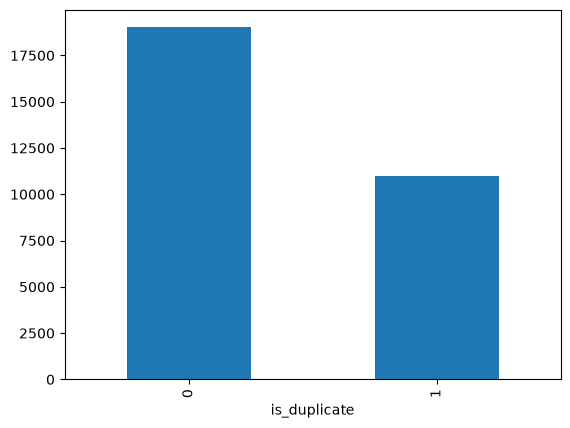

In [14]:
#Distribution of duplicate and non-duplicates questions

print(new_df['is_duplicate'].value_counts())
print((new_df['is_duplicate'].value_counts()/new_df['is_duplicate'].count())*100)
new_df['is_duplicate'].value_counts().plot(kind='bar')

In [15]:
#Repeated questions

qid = pd.Series(new_df['qid1'].tolist() + new_df['qid2'].tolist())
print("Number of unique questions",np.unique(qid).shape[0])
x = qid.value_counts() > 1
print("Number of questions getting repeated", x[x].shape[0])

Number of unique questions 55299
Number of questions getting repeated 3480


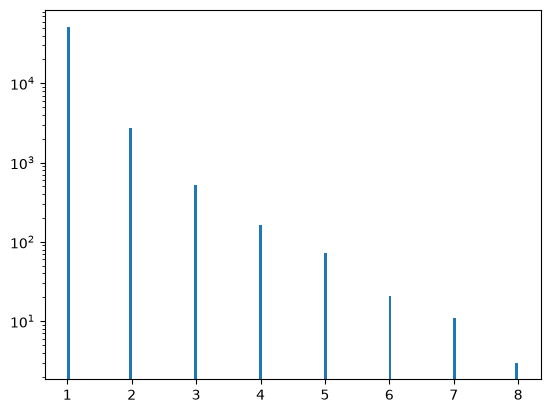

In [16]:
#Repeated questions histogram

plt.hist(qid.value_counts().values, bins = 160)
plt.yscale('log')
plt.show()

In [18]:
#Feature Engineering

#1. New columns with question1 and question2 lengths added to our current new_df dataframe.
new_df['q1len'] = new_df['question1'].str.len()
new_df['q2len'] = new_df['question2'].str.len()

In [19]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1len,q2len
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0,59,146
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0,35,50


In [20]:
#2. New columns which are question1 and 2 number of words in each row added to our new_df dataframe.
new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))

In [21]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1len,q2len,q1_num_words,q2_num_words
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120,25,17
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0,59,146,12,30
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0,35,50,5,9


In [22]:
#3. Calculating common words
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" "))) # took set(to avoid duplicate words) of words of quest1 and 2 rows and we did it by considering word when there is space after a character and spliting then.
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" "))) 
    return len(w1 & w2) #Took intersection of those set will give us common words.

In [26]:
#Just an example
set(map(lambda word: word.lower().strip(), 'I am poor but I want to invest. What should I do?'.split(" ")))

{'am', 'but', 'do?', 'i', 'invest.', 'poor', 'should', 'to', 'want', 'what'}

In [23]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1len,q2len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120,25,17,2
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0,59,146,12,30,0
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0,35,50,5,9,3


In [29]:
#4. Total words 
def total_word(row):
    w1 = set(map(lambda x: x.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda x: x.lower().strip(), row['question2'].split(" ")))
    return len(w1) + len(w2)

In [30]:
new_df['word_total'] = new_df.apply(total_word, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1len,q2len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11,24
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7,23
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120,25,17,2,34
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0,59,146,12,30,0,32
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0,35,50,5,9,3,13


In [31]:
#5. Word Share
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1len,q2len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,What is the best marketing automation tool for...,What is the best marketing automation tool for...,1,76,77,12,12,11,24,0.46
115086,115086,187729,187730,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...,0,49,57,12,15,7,23,0.30
327711,327711,454161,454162,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...,0,105,120,25,17,2,34,0.06
367788,367788,498109,491396,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...,0,59,146,12,30,0,32,0.00
151235,151235,237843,50930,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...,0,35,50,5,9,3,13,0.23


Minimum Characters 2
Maximum Characters 391
Average num of characters 59


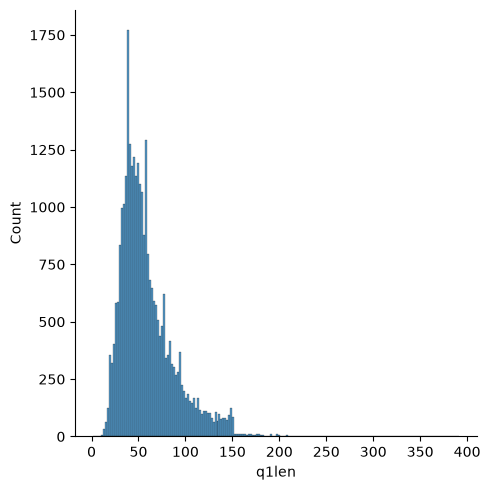

In [40]:
#We have added all the new 7 custom made features for our model to do better
#Analysis of features, let's do this first
sns.displot(new_df['q1len']) # EDA for seeing what is the avg no. of character of that q1
print("Minimum Characters", new_df['q1len'].min())
print("Maximum Characters", new_df['q1len'].max())
print("Average num of characters", int(new_df['q1len'].mean()))
    

Minimum Characters 6
Maximum Characters 1151
Average num of characters 60


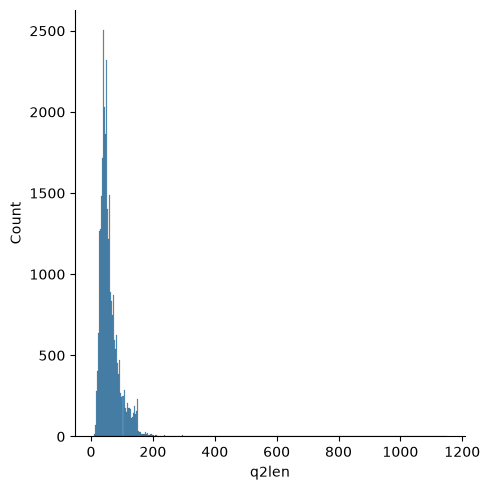

In [39]:
#We have added all the new 7 custom made features for our model to do better
#Analysis of features, let's do this first
sns.displot(new_df['q2len']) # EDA for seeing what is the avg no. of character of that q2
print("Minimum Characters", new_df['q2len'].min())
print("Maximum Characters", new_df['q2len'].max())
print("Average num of characters", int(new_df['q2len'].mean()))

Minimum words 1
Maximum words 72
Average num of characters 10


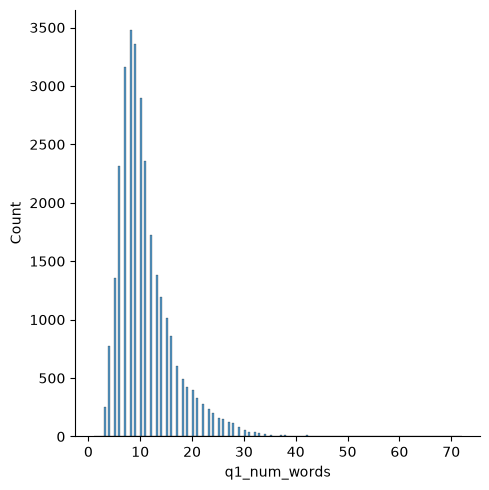

In [42]:
#Analysis of features, let's do this first
sns.displot(new_df['q1_num_words']) # EDA for seeing what is the avg no. of word of that q1
print("Minimum words", new_df['q1_num_words'].min())
print("Maximum words", new_df['q1_num_words'].max())
print("Average num of characters", int(new_df['q1_num_words'].mean()))

Minimum words 1
Maximum words 237
Average num of characters 11


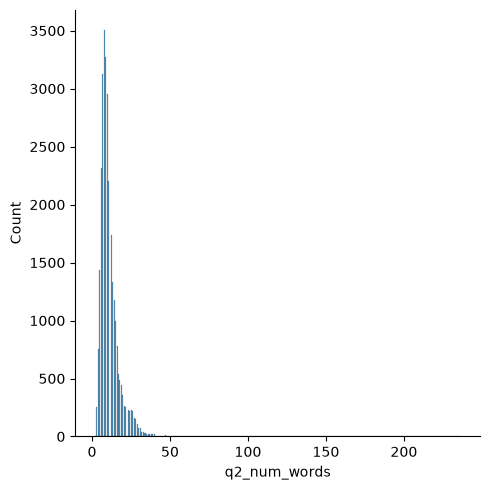

In [41]:
#Analysis of features, let's do this first
sns.displot(new_df['q2_num_words']) # EDA for seeing what is the avg no. of word of that q2
print("Minimum words", new_df['q2_num_words'].min())
print("Maximum words", new_df['q2_num_words'].max())
print("Average num of characters", int(new_df['q2_num_words'].mean()))

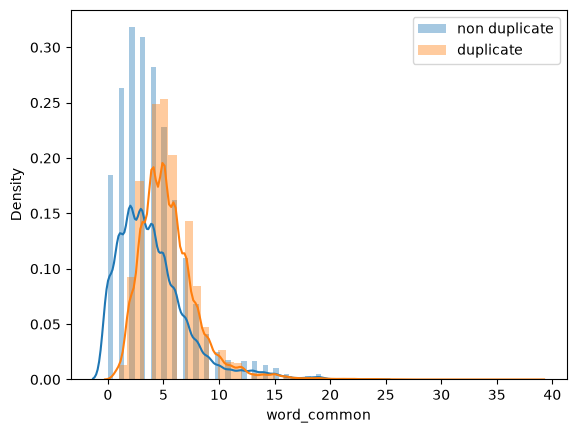

In [44]:
# common words
#Below figure shows that common words if they are below 4 words then having a duplicate is very less probable.
#Below figure shows that common words if they are above 4 words then having a duplicate is very high probable.
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_common'], label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_common'], label='duplicate')
plt.legend()
plt.show()

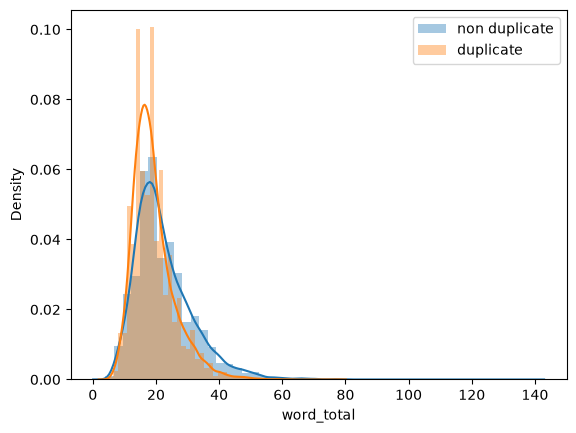

In [47]:
#Total Words
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_total'], label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_total'], label='duplicate')
plt.legend()
plt.show()

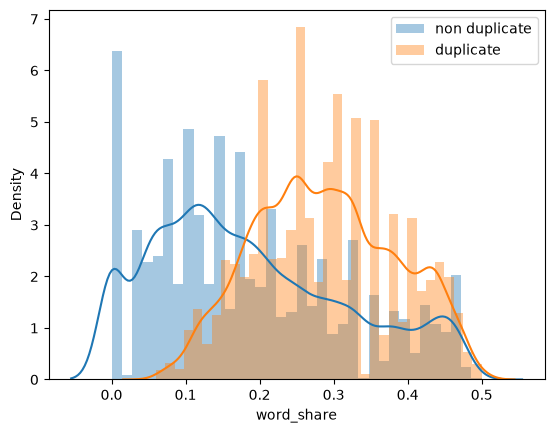

In [48]:
#Word Share
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_share'], label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_share'], label='duplicate')
plt.legend()
plt.show()

In [49]:
ques_df = new_df[['question1', 'question2']]
ques_df.head()

,question1,question2
398782,What is the best marketing automation tool for...,What is the best marketing automation tool for...
115086,I am poor but I want to invest. What should I do?,I am quite poor and I want to be very rich. Wh...
327711,I am from India and live abroad. I met a guy f...,T.I.E.T to Thapar University to Thapar Univers...
367788,Why do so many people in the U.S. hate the sou...,My boyfriend doesnt feel guilty when he hurts ...
151235,Consequences of Bhopal gas tragedy?,What was the reason behind the Bhopal gas trag...


In [50]:
final_df = new_df.drop(columns = ['id', 'qid1', 'qid2', 'question1', 'question2'])
print(final_df.shape)
final_df.head()

(30000, 8)


,is_duplicate,q1len,q2len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,1,76,77,12,12,11,24,0.46
115086,0,49,57,12,15,7,23,0.30
327711,0,105,120,25,17,2,34,0.06
367788,0,59,146,12,30,0,32,0.00
151235,0,35,50,5,9,3,13,0.23


In [54]:
#Now we will apply BOW (Bag Of Words) on my ques_df

from sklearn.feature_extraction.text import CountVectorizer
#merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)

In [55]:
temp_df1 = pd.DataFrame(q1_arr, index = ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index = ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 6000)

In [56]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 6008)


,is_duplicate,q1len,q2len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,76,77,12,12,11,24,0.46,0,0,...,0,0,0,0,0,0,0,0,0,0
115086,0,49,57,12,15,7,23,0.30,0,0,...,0,0,0,0,0,0,0,0,0,0
327711,0,105,120,25,17,2,34,0.06,0,0,...,0,0,0,0,0,0,0,0,0,0
367788,0,59,146,12,30,0,32,0.00,0,0,...,0,0,0,1,0,0,0,0,0,0
151235,0,35,50,5,9,3,13,0.23,0,0,...,0,0,0,0,0,0,0,0,0,0


In [58]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(final_df.iloc[:,1:].values, final_df.iloc[:,0].values, test_size = 0.2, random_state=1)

In [59]:
#See our model will improve significantly!!! Our last BOW practice we saw are RF was 71% and now is 77%...
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test, y_pred)

0.774

In [62]:
#See even model xgboost will improve significantly!!! 
#!pip install xgboost
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
accuracy_score(y_test, y_pred)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 10.7 MB/s  0:00:00 eta -:--:--


0.763

We are adding some more features, and we can make these a little bit more advanced.

1. Token Features:
   1. cwc - min: This is number of common words divided by minimum of words of q1 and q2. 
   2. cwc - max: This is number of common words divided by maximum of words of q1 and q2.
   3. csc - min: This is number of stop words divided by minimum of stopwords of q1 and q2.
   4. csc - max: This is number of stop words divided by maximum of stopwords of q1 and q2.
   5. ctc - min: This is number of common tokens divide by minimum of tokens of q1,q2
   6. ctc - max: This is number of common tokens divide by maximum of token of q1 and q2.
   7. last_word_equal: Last word equal of q1  and q2
   8. first_word equal: First word equal of q1 and q2

2. Length Bases features:
    1. mean_len: Mean of token of q1 and q2 (say)
    2. abs_len_diff: Absolute Diff of len of q1 and q2.
    3. longest_substr_ratio: q1: w1,w2,w3,w4 q2: w1,w2,w3,w4 longest substring is w1 and w2 divided by min of tokens of q1 and q2.

3. Fuzzy_features
Link to refer this concepts in detail: https://chairnerd.seatgeek.com/fuzzywuzzy-fuzzy-string-matching-in-python/
    1. fuzz_ratio: fuzz_ratio score from fuzzymwuzzy
    2. fuzz_partial_ratio: fuzz_partial_ratio from fuzzywuzzy
    3. token_sort_ratio: token_sort_ratio from fuzzywuzzy
    4. token_set_ratio: token_set_ratio from fuzzywuzzy

In [ ]:
#Getting started with these features included. Included in different notebook(BOW_Preprocessing_and_adv_Features.ipynb).